# Harmonic events from EEG
**CS1090A · Canvas Group 18 · Milestone 2: data wrangling and project redefinition**

**Group members:** Davis Bone, Rose Friedman, Ana Maria Ramirez Diaz, Trent Rogers, Payton Shen

**Repository:** https://github.com/davisbone/Harmonic-EEG/tree/ms2-lean

**Question:** Can 21 early EEG voltage features tell standard from deviant middle chords in participants the model was not trained on?

**In short:** 40 musicians listened to three-chord progressions while 64 scalp electrodes recorded EEG. Our cleaning (in `preprocess.py`, shown step by step in Section 3) keeps 32,935 middle-chord events from 27 participants. Each event becomes one row with 21 voltage features (84% standards, 16% deviants).

**How to run:** open this notebook from the repository root after `uv sync`. It uses the bundled results, or reads them from the published branch if you have only the notebook and network access. The saved outputs include a run of the raw-EEG demo. To reproduce that demo, install the preprocessing extra, obtain the raw files for `sub-002`, and set `RUN_DEMO = True` in Section 3.

**Use of generative AI:** see Section 5.

In [1]:
%matplotlib inline
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Use one complete set of results, locally or from the same GitHub branch.
GITHUB = "https://raw.githubusercontent.com/davisbone/Harmonic-EEG/ms2-lean/"
local_results = Path("results").is_dir()

def local_or_github(name):
    return Path(name) if local_results else GITHUB + name

events = pd.read_parquet(local_or_github("results/events.parquet"))
ledger = pd.read_csv(local_or_github("results/event_ledger.csv.gz"), keep_default_na=False)
audit = pd.read_csv(local_or_github("results/participant_audit.csv"))

WINDOWS = {"080_150": (0.080, 0.150), "150_250": (0.150, 0.250), "250_400": (0.250, 0.400)}
REGIONS = ["Lfront", "Rfront", "FCmid", "Cmid", "Pmid", "Ltemp", "Rtemp"]
PREDICTORS = [f"erp_{region}_{window}_uv" for region in REGIONS for window in WINDOWS]

assert events.event_id.is_unique and ledger.event_id.is_unique
assert events.event_id.tolist() == ledger.loc[ledger.included, "event_id"].tolist()
assert np.isfinite(events[PREDICTORS].to_numpy()).all()
plt.rcParams.update({"figure.figsize": (9, 3.5), "axes.spines.top": False, "axes.spines.right": False})
print(f"Loaded {len(events):,} events from {events.subject.nunique()} participants, {len(PREDICTORS)} EEG features.")

Loaded 32,935 events from 27 participants, 21 EEG features.


## 1. Getting the data

**Source:** [NEMAR on003570](https://doi.org/10.82901/nemar.on003570), version 1.0.0 (a mirror of [OpenNeuro ds003570](https://doi.org/10.18112/openneuro.ds003570.v1.0.0)), from [Faller et al. (2021)](https://doi.org/10.1016/j.neuroimage.2021.118458). It has 40 participants, each with 64 EEG electrodes recorded at 2,048 samples per second for about 40 minutes.

**The experiment:** each trial is three chords, about 400 ms apart. The middle chord is either the **standard** (the progression repeated in that block) or a **deviant**. An *exemplar deviant* changes the chord's inversion but keeps its harmonic role; a *function deviant* swaps in a chord with a different role. Participants pressed a button when they heard a deviant. Our binary target pools both deviant types.

`data_manifest.json` lists every file in the release with its size and download link. `preprocess.download()` fetches them.

In [2]:
manifest = pd.read_json(local_or_github("data_manifest.json"))
print(f"Raw release: {len(manifest)} files, {manifest['size'].sum() / 1e9:.1f} GB")
print(f"Cleaned table: {events.shape[0]:,} rows x {events.shape[1]} columns, "
      f"{events.memory_usage(deep=True).sum() / 1e6:.1f} MB in memory")

DATA_DIR = Path("Data/on003570")
DOWNLOAD = False  # about 39 GB; only needed to rerun the cleaning
if DOWNLOAD:
    import preprocess
    preprocess.download(DATA_DIR)

Raw release: 328 files, 38.8 GB
Cleaned table: 32,935 rows x 30 columns, 8.9 MB in memory


## 2. Understanding the data

**One row = one middle chord heard by one participant.** The 21 feature columns are EEG voltages in microvolts (µV). Each one averages a group of electrodes (a scalp region) over a time window after the middle chord, measured relative to the 100 ms before it. Columns are named `erp_<region>_<window>_uv`; ERP (event-related potential) means voltage lined up to an event.

| Region | Scalp area | Electrodes |
|---|---|---|
| `Lfront` / `Rfront` | Left / right frontal | AF3, F3, F5, F7, FC3, FC5 / AF4, F4, F6, F8, FC4, FC6 |
| `FCmid` | Front-centre midline | Fz, F1, F2, FC1, FCz, FC2 |
| `Cmid` | Centre midline | C1, Cz, C2, CP1, CPz, CP2 |
| `Pmid` | Back (parietal) midline | P1, Pz, P2, PO3, POz, PO4 |
| `Ltemp` / `Rtemp` | Left / right temporal | T7, TP7, P7, P9 / T8, TP8, P8, P10 |

Windows: 80–150, 150–250 and 250–400 ms after the middle chord.

| Column | Meaning | Used as a predictor? |
|---|---|---|
| `erp_*_uv` (21) | Regional voltage averages | **Yes, the only predictors** |
| `target` | 0 = standard, 1 = deviant | The outcome |
| `condition` | standard / exemplar_dev / function_dev | No (it is the label) |
| `subject` | Participant ID | No; used to group cross-validation folds |
| `trial`, `block`, `onset_s`, `event_id` | When the chord happened | No; they leak the label (see 3.4) |
| `source_available` | The raw recording covers this event | No |
| `group` | `Cl` = classical, `Imp` = improvising musician | No |

In [3]:
display(events.head())
print("Shape:", events.shape)
display(events.dtypes.astype(str).rename("dtype").to_frame())
display(events.describe().T[["mean", "std", "min", "max"]].round(2))

,subject,trial,event_id,block,onset_s,condition,target,source_available,erp_Lfront_080_150_uv,erp_Lfront_150_250_uv,...,erp_Pmid_080_150_uv,erp_Pmid_150_250_uv,erp_Pmid_250_400_uv,erp_Ltemp_080_150_uv,erp_Ltemp_150_250_uv,erp_Ltemp_250_400_uv,erp_Rtemp_080_150_uv,erp_Rtemp_150_250_uv,erp_Rtemp_250_400_uv,group
0,sub-001,12,sub-001_trial-0012,1,21.140137,standard,0,True,-7.683005,-4.475911,...,10.962259,9.908422,6.281861,9.964424,5.417424,2.860510,3.667793,-4.211687,-3.682085,Cl
1,sub-001,13,sub-001_trial-0013,1,22.739746,standard,0,True,-9.713874,-10.230387,...,7.846989,9.071742,10.685245,5.098308,2.847263,-1.191390,9.847172,8.353021,10.835022,Cl
2,sub-001,14,sub-001_trial-0014,1,24.346191,standard,0,True,5.555457,4.078070,...,-5.138405,-5.918432,-1.350917,-2.626311,-3.194741,-5.064069,-0.351945,-4.007674,-6.119110,Cl
3,sub-001,15,sub-001_trial-0015,1,25.940430,standard,0,True,2.965287,4.661370,...,-3.966921,-5.608922,-2.380754,7.052797,1.664525,1.609157,3.351040,-2.921806,1.408856,Cl
4,sub-001,16,sub-001_trial-0016,1,27.538086,standard,0,True,-2.523194,2.249280,...,1.187517,-6.144309,2.128830,2.096683,0.160742,-1.100486,4.671220,-2.593057,1.613290,Cl


Shape: (32935, 30)


,dtype
subject,str
trial,int64
event_id,str
block,int64
onset_s,float64
condition,str
target,int64
source_available,bool
erp_Lfront_080_150_uv,float64
erp_Lfront_150_250_uv,float64


,mean,std,min,max
trial,715.01,413.56,10.00,1440.00
block,4.47,2.29,1.00,8.00
onset_s,1167.38,675.82,21.11,2475.19
target,0.16,0.37,0.00,1.00
erp_Lfront_080_150_uv,-0.61,3.86,-27.62,23.13
erp_Lfront_150_250_uv,-0.49,4.22,-34.03,26.59
erp_Lfront_250_400_uv,-0.51,4.78,-34.38,33.22
erp_Rfront_080_150_uv,-0.72,3.99,-25.24,36.01
erp_Rfront_150_250_uv,-0.59,4.40,-35.86,40.91
erp_Rfront_250_400_uv,-0.60,4.97,-39.29,47.88


## 3. Cleaning and preprocessing

Raw EEG is a continuous voltage trace, not a table, so most of the cleaning happens before there are any rows. `preprocess.py` does it in eight steps; the optional demo walks through each step on one participant (`sub-002`). Event markers locate the middle chords. Cleaning and QC decisions do not use their condition labels or response timing.

### 3.1 Step by step on one participant

In [4]:
SUBJECT = "sub-002"
RUN_DEMO = False  # Set True after downloading this participant and installing the preprocessing extra.
if RUN_DEMO:
    import preprocess
else:
    print("Using the bundled results. Set RUN_DEMO = True to rerun the raw-EEG demo.")

**Step 1: load.** Read the raw voltages, the list of chord events, and the boundaries of the 8 recording blocks (the session was recorded in 8 pieces and joined together).

In [5]:
if RUN_DEMO:
    raw, trials, blocks, fraction = preprocess.load_participant(DATA_DIR, SUBJECT)
    print(f"{SUBJECT}: {len(raw.ch_names)} electrodes x {raw.n_times:,} samples, "
          f"{fraction:.0%} of the recording present, {len(blocks)} blocks, {len(trials)} trials")
    display(trials.head(3))

sub-002: 64 electrodes x 4,919,296 samples, 100% of the recording present, 8 blocks, 1440 trials


,subject,trial,event_id,block,onset_s,condition,target,source_available
0,sub-002,1,sub-002_trial-0001,1,7.918457,standard,0,True
1,sub-002,2,sub-002_trial-0002,1,9.516602,standard,0,True
2,sub-002,3,sub-002_trial-0003,1,11.122559,standard,0,True


**Step 2: downsample and filter, block by block.** 2,048 samples/s is more than we need, so we keep every 8th sample (256/s) after smoothing to avoid aliasing. A **high-pass filter** (0.1 Hz) removes slow drift and a **notch filter** removes 60 Hz power-line hum. Filtering each block separately avoids smearing across the joins.

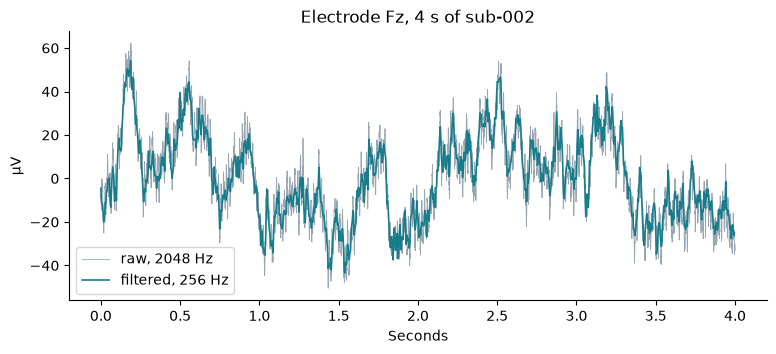

In [6]:
if RUN_DEMO:
    down = preprocess.downsample_and_filter(raw, blocks)
    t0, seconds = 60, 4
    native = raw.get_data(picks=["Fz"], start=t0 * 2048, stop=(t0 + seconds) * 2048)[0] * 1e6
    clean = down[0].get_data(picks=["Fz"], start=t0 * 256, stop=(t0 + seconds) * 256)[0] * 1e6
    fig, ax = plt.subplots()
    ax.plot(np.arange(len(native)) / 2048, native - native.mean(), color="#99a7b2", lw=0.6, label="raw, 2048 Hz")
    ax.plot(np.arange(len(clean)) / 256, clean - clean.mean(), color="#167d8d", lw=1.2, label="filtered, 256 Hz")
    ax.set(title=f"Electrode Fz, {seconds} s of {SUBJECT}", xlabel="Seconds", ylabel="µV"); ax.legend()
    plt.show()

**Step 3: find bad electrodes.** An electrode is bad if it is dead (almost no signal) or if [PyPREP](https://pyprep.readthedocs.io/) flags it as noisy (too large, too much high-frequency noise, or out of step with its neighbours) in at least half the recording.

**Step 4: repair and re-reference.** Bad electrodes are rebuilt from their neighbours (**interpolation**). Then every electrode is re-expressed relative to the average of all 64 (**average reference**). A participant with more than 6 bad electrodes is dropped, because heavy repair weakens the rest of the cleaning.

In [7]:
if RUN_DEMO:
    bad = preprocess.find_bad_channels(down)
    print(f"Bad electrodes: {bad} ({len(bad)} of 64; the limit is {preprocess.MAX_BAD_CHANNELS})")
    assert len(bad) <= preprocess.MAX_BAD_CHANNELS
    for block in down:
        preprocess.repair(block, bad)

Bad electrodes: ['Fp1', 'FC6', 'C6', 'T8'] (4 of 64; the limit is 6)


**Step 5: remove eye, muscle and heart artifacts with ICA.** Like PCA, independent component analysis (ICA) rewrites the 64 electrode signals as a set of components, but it looks for statistically *independent* sources instead of maximum variance. Blinks and muscle activity tend to come out as their own components. An automatic classifier, [ICLabel](https://doi.org/10.1016/j.neuroimage.2019.05.026), labels each component; we remove the ones it labels as an artifact with probability above 0.8.

In [8]:
if RUN_DEMO:
    ica, labels = preprocess.fit_ica(down)
    components = pd.DataFrame({"ICLabel": labels["labels"], "probability": labels["y_pred_proba"].round(2)})
    components["removed"] = components.index.isin(ica.exclude)
    print(f"{len(ica.exclude)} of {len(components)} components removed")
    display(components.value_counts(["ICLabel", "removed"]).rename("components").to_frame())

Use rng= instead of random_state= in new code


6 of 30 components removed


,,components
ICLabel,removed,
brain,False,11
channel noise,False,7
other,False,5
eye blink,True,2
muscle artifact,True,2
channel noise,True,2
muscle artifact,False,1


**Step 6: cut epochs.** Apply the ICA correction, low-pass filter at 40 Hz, and cut a 500 ms **epoch** around each middle chord (100 ms before to 400 ms after). Filters need data on both sides, so events within about 21 s of a block edge are skipped. One last repair pass rebuilds any electrode that is the noisiest one in more than 5% of epochs.

In [9]:
if RUN_DEMO:
    demo_ledger, centers = preprocess.epoch_centers(trials, blocks, preprocess.edge_guard(preprocess.LP))
    epochs = preprocess.clean_epochs(down, ica, demo_ledger, centers)
    epochs, bad, extra = preprocess.repair_intermittent(epochs, raw, bad)
    print(f"Epochs: {epochs.shape} (events x electrodes x samples); skipped near block edges: "
          f"{(~demo_ledger.boundary_eligible).sum()}; extra repaired electrodes: {extra}")

Epochs: (1288, 64, 128) (events x electrodes x samples); skipped near block edges: 152; extra repaired electrodes: []


**Step 7: quality check.** Reject an epoch if any electrode swings more than 150 µV peak to peak (a sign of movement or electrode artifacts), is flat (under 1 µV), or has missing values. A participant who loses more than 40% of epochs would be dropped (nobody did).

Passed: 1,265 of 1,288 epochs (98.2%)


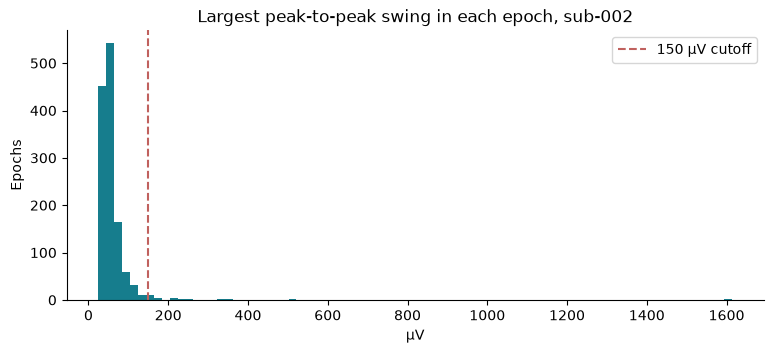

In [10]:
if RUN_DEMO:
    qc = preprocess.quality_check(epochs)
    passed = (qc.signal_reason == "").to_numpy()
    print(f"Passed: {passed.sum():,} of {len(qc):,} epochs ({passed.mean():.1%})")
    fig, ax = plt.subplots()
    ax.hist(qc.max_ptp_uv, bins=80, color="#167d8d")
    ax.axvline(preprocess.REJECT_UV, color="#c0615e", ls="--", label="150 µV cutoff")
    ax.set(title=f"Largest peak-to-peak swing in each epoch, {SUBJECT}", xlabel="µV", ylabel="Epochs"); ax.legend()
    plt.show()

**Step 8: features.** Subtract each electrode's average over the 100 ms before the middle chord (the **baseline**), average the electrodes in each region, then average each of the three time windows: 7 regions × 3 windows = 21 numbers. The plot shows one real event; the check confirms the demo matches the published event IDs and reproduces their features to numerical precision.

Reproduced 1,265 published event IDs and their 21 features.


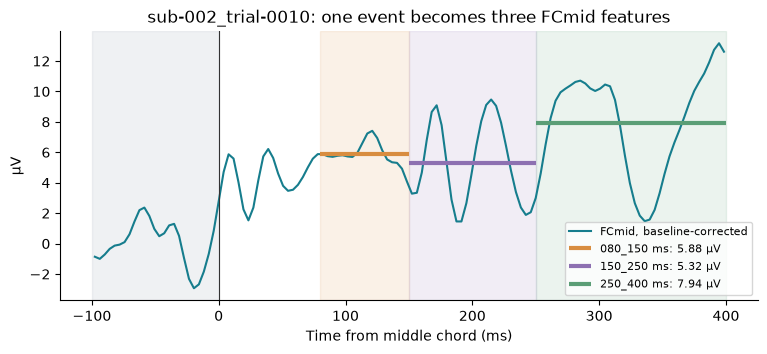

In [11]:
if RUN_DEMO:
    features = preprocess.erp_features(epochs[passed], raw.ch_names)
    published = events.loc[events.subject == SUBJECT]
    demo_ids = demo_ledger.loc[demo_ledger.boundary_eligible, "event_id"].to_numpy()[passed]
    assert len(bad) <= preprocess.MAX_BAD_CHANNELS and passed.mean() >= preprocess.MIN_RETENTION
    np.testing.assert_array_equal(demo_ids, published.event_id.to_numpy())
    np.testing.assert_allclose(features[PREDICTORS], published[PREDICTORS], rtol=0, atol=1e-8)
    print(f"Reproduced {len(demo_ids):,} published event IDs and their 21 features.")

    times = preprocess.epoch_offsets() / preprocess.SFREQ
    picks = [raw.ch_names.index(n) for n in preprocess.ROIS["FCmid"]]
    trace = epochs[passed][0][picks].mean(axis=0) * 1e6
    corrected = trace - trace[times < 0].mean()
    fig, ax = plt.subplots()
    ax.plot(times * 1000, corrected, color="#167d8d", label="FCmid, baseline-corrected")
    ax.axvspan(-100, 0, color="#99a7b2", alpha=.15)
    for (window, (a, b)), color in zip(WINDOWS.items(), ["#d88d40", "#8d70b1", "#5b9e76"]):
        value = features.loc[0, f"erp_FCmid_{window}_uv"]
        ax.axvspan(a * 1000, b * 1000, color=color, alpha=.12)
        ax.hlines(value, a * 1000, b * 1000, color=color, lw=3, label=f"{window} ms: {value:.2f} µV")
    ax.axvline(0, color="#333", lw=.8)
    ax.set(title=f"{demo_ids[0]}: one event becomes three FCmid features",
           xlabel="Time from middle chord (ms)", ylabel="µV")
    ax.legend(fontsize=8); plt.show()

**All participants.** `preprocess.build()` runs these steps for all 40 participants (about 75 minutes) and writes a new copy of the three result files. The optional cell writes to `Data/ms2-rebuild` so the bundled results stay available. The event ledger keeps every one of the 57,600 candidate events with the reason it was or was not kept.

In [12]:
REBUILD = False
if REBUILD:
    import preprocess
    preprocess.build(DATA_DIR, "Data/ms2-rebuild")

### 3.2 What was removed, and why

Ten recordings in the public release are cut off (less than half the EEG exists), and two more are about 92% complete (we keep the part that exists). Three participants had more than 6 bad electrodes (`sub-006`: 7, `sub-023`: 9, `sub-035`: 13). So **40 − 10 − 3 = 27 participants** remain.

**Missing data:** we never fill in missing EEG. Every event that is not in the table has a reason in the ledger, and the final table has no missing values.

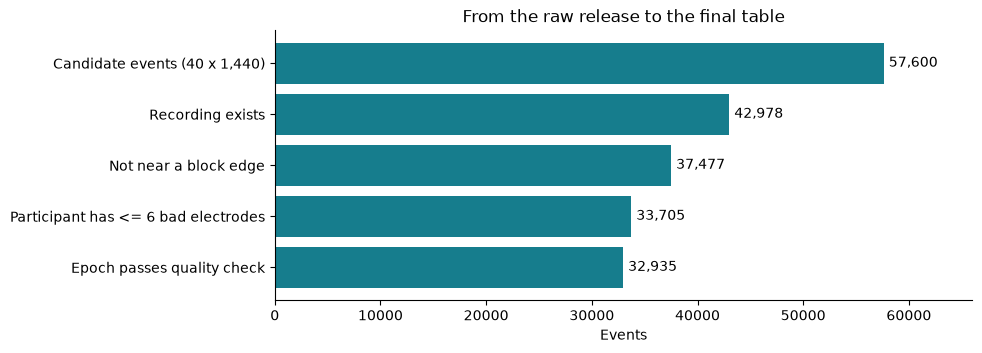

,events removed
reason,
source_severely_truncated,14400
filter_edge_guard,5501
participant:too_many_bad_channels,3772
signal:amplitude,770
source_unavailable,222


Missing values in the final table: 0


In [13]:
flow = pd.Series({
    "Candidate events (40 x 1,440)": len(ledger),
    "Recording exists": int(ledger.source_available.sum()),
    "Not near a block edge": int(ledger.boundary_eligible.sum()),
    "Participant has <= 6 bad electrodes": int((ledger.boundary_eligible & (ledger.reason != "participant:too_many_bad_channels")).sum()),
    "Epoch passes quality check": int(ledger.included.sum()),
})
fig, ax = plt.subplots()
ax.barh(flow.index[::-1], flow.values[::-1], color="#167d8d")
for i, n in enumerate(flow.values[::-1]):
    ax.text(n + 500, i, f"{n:,}", va="center")
ax.set(title="From the raw release to the final table", xlabel="Events", xlim=(0, 66000))
plt.show()

display(ledger[~ledger.included].reason.value_counts().rename("events removed").to_frame())
print("Missing values in the final table:", int(events.isna().sum().sum()))

### 3.3 Class balance, feature scale, and unusual values

**Class imbalance:** 84% of events are standards. Always guessing "standard" is 84% accurate but useless, so we will use AUC and balanced accuracy, not accuracy.

**Scale:** all 21 features are in the same unit (µV) with similar spreads (SD about 3.6–6.1 µV), but we will still standardize them inside each training fold for regularized models.

**Unusual values:** a small tail is large: about 0.65% of events have some feature beyond ±30 µV, mostly from a few participants (41 of the 48 events beyond ±50 µV are from `sub-036`). They passed the 150 µV rule, so they could be leftover drift or muscle noise, but nothing in the data proves they are errors. We keep them rather than trim data to improve a score, and in Milestone 3 we will check whether results depend on them.

condition
standard        27663
exemplar_dev     2657
function_dev     2615 
Deviant share: 16.0%
Events with a feature beyond ±30 µV: 215 (0.65%); beyond ±50 µV: 48
By participant (beyond ±50 µV): {'sub-036': 41, 'sub-020': 3, 'sub-017': 2, 'sub-029': 2}


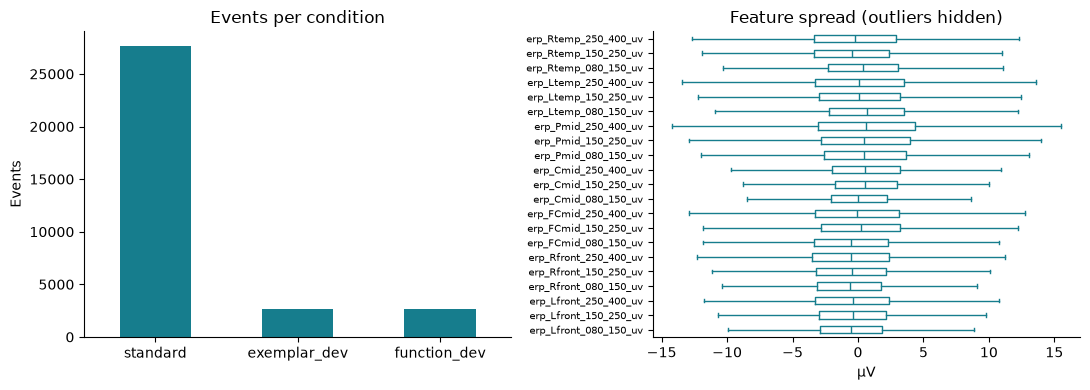

In [14]:
counts = events.condition.value_counts()
print(counts.to_string(), f"\nDeviant share: {events.target.mean():.1%}")

largest = events[PREDICTORS].abs().max(axis=1)
print(f"Events with a feature beyond ±30 µV: {(largest > 30).sum()} ({(largest > 30).mean():.2%}); "
      f"beyond ±50 µV: {(largest > 50).sum()}")
print("By participant (beyond ±50 µV):", events.subject[largest > 50].value_counts().to_dict())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
counts.plot.bar(ax=axes[0], color="#167d8d", rot=0)
axes[0].set(title="Events per condition", ylabel="Events", xlabel="")
events[PREDICTORS].plot.box(ax=axes[1], vert=False, showfliers=False, color="#167d8d")
axes[1].set(title="Feature spread (outliers hidden)", xlabel="µV")
axes[1].tick_params(axis="y", labelsize=7)
plt.tight_layout(); plt.show()

### 3.4 Information leakage

- The trial number alone identifies the condition across participants in this release (checked below). Event IDs contain the trial number, and block and onset time also encode the sequence. Holding out participants does not fix this, so these columns are never predictors.
- The cleaning never uses the labels, and the share of epochs rejected for amplitude is about the same in each condition (below).
- Participants pressed a button for deviants, and some response-related markers occur before 400 ms, so the 250–400 ms window may partly reflect getting ready to press. We will also test a model without that window.
- Scaling and class weights will be fit on training folds only.

In [15]:
print("Each trial number has the same condition for every participant:",
      ledger.groupby("trial").condition.nunique().max() == 1)
checked = ledger[ledger.boundary_eligible & (ledger.reason != "participant:too_many_bad_channels")]
display((checked.reason == "signal:amplitude").groupby(checked.condition).mean().round(3)
        .rename("share rejected for amplitude").to_frame())

Each trial number has the same condition for every participant: True


,share rejected for amplitude
condition,
exemplar_dev,0.019
function_dev,0.021
standard,0.023


### 3.5 A first look at condition differences

Average each participant's events by condition, then average the 27 participants. Deviants differ from standards by up to about 1.3 µV on average, while single events vary by 4–6 µV, so single events overlap heavily. That is why this is a hard prediction problem.

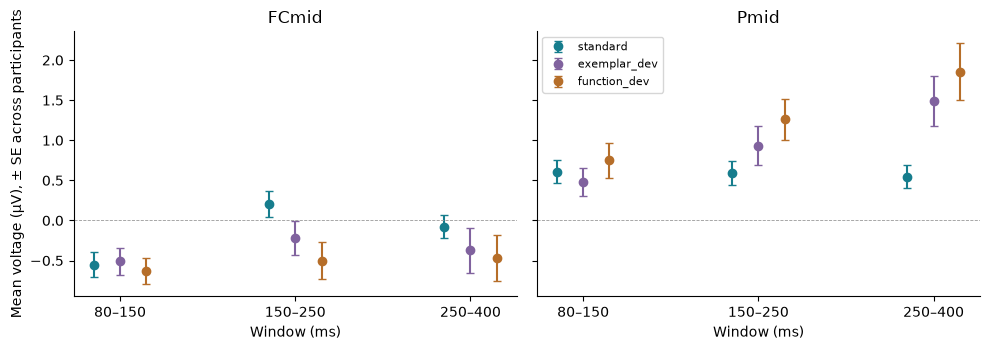

In [16]:
means = events.groupby(["subject", "condition"])[PREDICTORS].mean().groupby("condition")
avg, sem = means.mean(), means.sem()
labels = ["80–150", "150–250", "250–400"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, region in zip(axes, ["FCmid", "Pmid"]):
    cols = [f"erp_{region}_{w}_uv" for w in WINDOWS]
    for cond, color, shift in [("standard", "#167d8d", -.15), ("exemplar_dev", "#80629e", 0), ("function_dev", "#b66e29", .15)]:
        ax.errorbar(np.arange(3) + shift, avg.loc[cond, cols], yerr=sem.loc[cond, cols], fmt="o", color=color, capsize=3, label=cond)
    ax.axhline(0, color="#999", lw=.6, ls="--")
    ax.set_xticks(range(3), labels); ax.set(title=region, xlabel="Window (ms)")
axes[0].set_ylabel("Mean voltage (µV), ± SE across participants"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 4. Project question

**Question:** Can 21 early EEG voltage features tell standard from deviant middle chords in participants the model was not trained on?

**How we will know:** *yes* if a model evaluated with cross-validation grouped by participant gets a held-out ROC AUC above 0.5, with a bootstrap confidence interval (resampling held-out participants) that excludes 0.5, and beats always-guess-standard on balanced accuracy. Otherwise we have not shown above-chance prediction.

A *yes* would show the EEG carries the information, not why: standards and deviants also differ in sound, attention and button presses.

The plan is to compare the always-standard baseline, regularized logistic regression, and random forest. Shrinkage LDA is a candidate outside method for the group to confirm. We will check whether results depend on the 250–400 ms window and explore which regions and windows are informative and how the two deviant types differ. These are follow-up analyses.

The split below keeps each participant entirely in training or entirely in testing. No model is fit yet. The cleaning uses each participant's available unlabeled recording separately, and zero-phase filters use samples on both sides of an event. This is an offline prediction task.

In [17]:
from sklearn.model_selection import GroupKFold

folds = []
for fold, (train, test) in enumerate(GroupKFold(n_splits=5).split(events[PREDICTORS], events.target, events.subject), 1):
    train_people, test_people = set(events.subject.iloc[train]), set(events.subject.iloc[test])
    assert train_people.isdisjoint(test_people)
    folds.append({"fold": fold, "train participants": len(train_people), "test participants": len(test_people),
                  "train events": len(train), "test events": len(test)})
display(pd.DataFrame(folds))

,fold,train participants,test participants,train events,test events
0,1,21,6,25747,7188
1,2,21,6,25700,7235
2,3,22,5,26762,6173
3,4,22,5,26760,6175
4,5,22,5,26771,6164


## 5. References and use of generative AI

**Data and studies**
- Goldman, A., Jackson, T., & Sajda, P. (2026). *EEG: Improvisation and Musical Structures* (v1.0.0) [Dataset]. NEMAR on003570. https://doi.org/10.82901/nemar.on003570 (mirror of OpenNeuro ds003570, https://doi.org/10.18112/openneuro.ds003570.v1.0.0)
- Faller, J., Goldman, A., Lin, Y., McIntosh, J. R., & Sajda, P. (2021). Spatiospectral brain networks reflective of improvisational experience. *NeuroImage*, 242, 118458. https://doi.org/10.1016/j.neuroimage.2021.118458
- Goldman, A., Jackson, T., & Sajda, P. (2020). Improvisation experience predicts how musicians categorize musical structures. *Psychology of Music*, 48(1), 18–34. https://doi.org/10.1177/0305735618779444

**Software and methods**
- Gramfort, A., et al. (2013). MEG and EEG data analysis with MNE-Python. *Frontiers in Neuroscience*, 7, 267. https://doi.org/10.3389/fnins.2013.00267
- Bigdely-Shamlo, N., et al. (2015). The PREP pipeline. *Frontiers in Neuroinformatics*, 9, 16. https://doi.org/10.3389/fninf.2015.00016 (PyPREP: https://pyprep.readthedocs.io/)
- Ablin, P., Cardoso, J.-F., & Gramfort, A. (2018). Faster independent component analysis by preconditioning with Hessian approximations. *IEEE Transactions on Signal Processing*, 66(15), 4040–4049. https://doi.org/10.1109/TSP.2018.2844203
- Pion-Tonachini, L., Kreutz-Delgado, K., & Makeig, S. (2019). ICLabel. *NeuroImage*, 198, 181–197. https://doi.org/10.1016/j.neuroimage.2019.05.026; Li, A., et al. (2022). MNE-ICALabel. *Journal of Open Source Software*, 7(76), 4484. https://doi.org/10.21105/joss.04484
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *JMLR*, 12, 2825–2830; plus NumPy, SciPy, pandas and Matplotlib.

**Generative AI**
- **OpenAI Codex** (GPT-6 Astra, GPT-6.1 Sol, GPT-6 Luna; November 2026): earlier preprocessing prototype and the first full version of the pipeline, notebook and documentation; technical review.
- **Anthropic Claude Code** (Claude Opus 5.5; November 2026): cross-review of preprocessing choices; condensing the pipeline into `preprocess.py` and restructuring this notebook around a step-by-step demo; wording edits.
- **Google Antigravity** (Gemini 4 Argon; November 2026): review, chart and citation updates.